[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/S05_07_reto_ocupacion.ipynb)

# S05_07 · Reto PBL «¿La ocupación depende de esto?» (plantilla del cuaderno entregable)
**Sprint 5 · Matemáticas y estadística en código · ⏱ 3 h (PBL)**

📖 *¿El código se hace largo? Léelo [explicado por escrito](https://github.com/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S05/2_Practica/codigo_explicado/S05_07_reto_ocupacion.md): recorrido, glosario y qué hace cada celda.* <!--codigo-explicado-->

## Pregunta del cliente
*TurisData Canarias* nos pregunta: **«¿Cuánto cambia la ocupación diaria cuando hace más calor y cuando el día es festivo?
¿Debemos planificar personal y precios teniendo en cuenta la temperatura?»**

## Qué debes entregar (este mismo cuaderno, completo)
1. **Base de datos poblada:** un archivo `turisdata_reto.db` con la serie diaria, y los datos leídos desde Python con SQL.
2. **Regresión lineal desde cero** con descenso del gradiente (simple y con controles), sin `scikit-learn` en la implementación.
3. **Contraste con una librería** (`statsmodels`) y comparación de coeficientes.
4. **Análisis estadístico** con contrastes e intervalos de confianza.
5. **Respuesta al cliente** (máx. 150 palabras) con recomendación, límites de lo que se puede afirmar y una nota de IA responsable.

Los **puntos de control** (`assert`) te avisan si algo no cuadra; el análisis y la respuesta se evalúan con la rúbrica del curso
(corrección técnica, reproducibilidad, análisis y comunicación al cliente, IA responsable).

> Las celdas con `...` / `# TODO` son tuyas. Puedes reutilizar el código de los cuadernos S05_03 y S05_05.
> Los datos son sintéticos: las conclusiones son para practicar, no estadísticas reales.

In [1]:
# Preparación (ejecuta esta celda siempre la primera)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta


In [2]:
import os
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

SEMILLA = 42
RUTA_BD = "turisdata_reto.db"        # el archivo que entregarás junto al cuaderno

## 1 · Base de datos: cargar y consultar
Crea la base `turisdata_reto.db` con una tabla `ocupacion_diaria` (a partir de `ocupacion_diaria.csv`) y un índice sobre
`fecha`. Después **lee los datos desde la base con SQL** en un DataFrame `diaria` que incluya una columna `mes` (entero 1-12).

In [3]:
# TODO: to_sql con if_exists="replace"; CREATE INDEX IF NOT EXISTS ... ON ocupacion_diaria(fecha); SELECT ..., CAST(SUBSTR(fecha, 6, 2) AS INTEGER) AS mes
datos = pd.read_csv(dato("ocupacion_diaria.csv"))
con = sqlite3.connect(RUTA_BD)
datos.to_sql("ocupacion_diaria", con, if_exists="replace", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_ocupacion_fecha ON ocupacion_diaria(fecha)")
con.commit()
diaria = pd.read_sql_query(
    "SELECT *, CAST(SUBSTR(fecha, 6, 2) AS INTEGER) AS mes FROM ocupacion_diaria", con)
assert os.path.exists(RUTA_BD), "Debe existir el archivo turisdata_reto.db"
assert len(diaria) == 1096, f"Deben leerse 1096 días y has leído {len(diaria)}"
assert "mes" in diaria.columns and diaria["mes"].between(1, 12).all(), "Falta la columna mes (1-12)"
assert con.execute("SELECT COUNT(*) FROM sqlite_master WHERE type='index' AND name='idx_ocupacion_fecha'").fetchone()[0] == 1, "Falta el índice idx_ocupacion_fecha"
print("Punto de control 1 superado")

Punto de control 1 superado


## 2 · Primer vistazo a los datos
Describe la serie (media, dispersión, meses de mayor y menor ocupación) y dibuja **al menos dos gráficos** con títulos y ejes
en español (por ejemplo, ocupación por mes y ocupación frente a temperatura). Escribe debajo 2–3 observaciones.

count    1096.000000
mean       68.488139
std         9.614882
min        47.300000
25%        61.400000
50%        67.700000
75%        75.000000
max        96.800000
Name: ocupacion_pct, dtype: float64
mes
1     78.8
2     77.6
3     74.5
4     70.1
5     62.6
6     60.8
7     63.0
8     62.1
9     60.1
10    63.3
11    70.8
12    78.6
Name: ocupacion_pct, dtype: float64
mes
9     60.1
6     60.8
8     62.1
5     62.6
7     63.0
10    63.3
4     70.1
11    70.8
3     74.5
2     77.6
12    78.6
1     78.8
Name: ocupacion_pct, dtype: float64


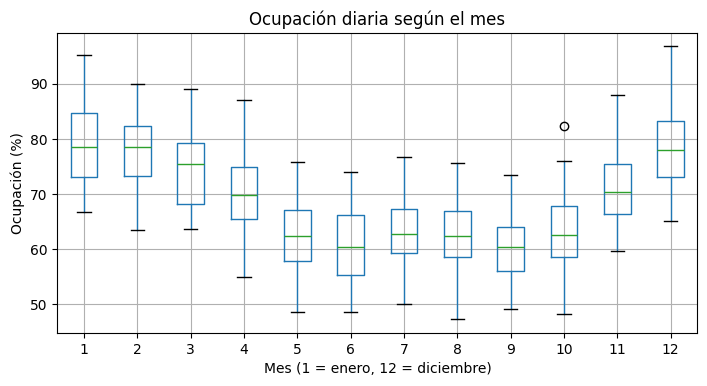

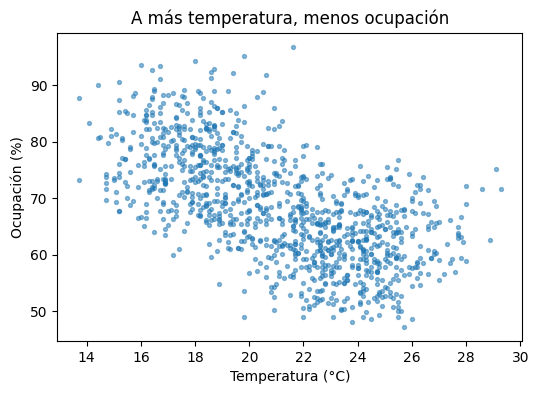

In [4]:
# TODO: describe(), una media por mes con groupby y dos gráficos (boxplot por mes y dispersión temperatura-ocupación)
print(diaria["ocupacion_pct"].describe())

medias_mes = diaria.groupby("mes")["ocupacion_pct"].mean()
print(medias_mes.round(1))
print(medias_mes.sort_values().round(1))

diaria.boxplot(column="ocupacion_pct", by="mes", figsize=(8, 4))
plt.suptitle("")
plt.title("Ocupación diaria según el mes")
plt.xlabel("Mes (1 = enero, 12 = diciembre)")
plt.ylabel("Ocupación (%)")
plt.show()

plt.figure(figsize=(6, 4))
plt.scatter(diaria["temperatura_c"], diaria["ocupacion_pct"], s=8, alpha=0.5)
plt.title("A más temperatura, menos ocupación")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Ocupación (%)")
plt.show()


**Mis observaciones (escribe aquí):**
- En diciembre, enero y febrero la ocupación media es más alta, alrededor de 78.8%.
- En el gráfico de puntos a más temperatura baja la ocupación.
- Viendo los gráficos no tenemos claro si la causa es la temperatura.

## 3 · Regresión lineal desde cero (descenso del gradiente)
Implementa `gradiente_mse(X, y, w)` y `entrenar(X, y, tasa, epocas)` (puedes basarte en S05_03; **no uses scikit-learn aquí**).
Ajusta dos modelos:
- **Modelo simple:** `ocupacion ~ temperatura` (variable estandarizada; deshaz la estandarización para dar la pendiente en puntos por °C).
- **Modelo con control:** `ocupacion ~ temperatura + festivo + indicadores de mes` (11 columnas de meses; estandariza todas las variables;
  usa unas 2.000 épocas con tasa 0,1).

Guarda `pendiente_simple` (puntos por °C), `efecto_temp_control` y `efecto_festivo_control` (ambos en puntos, ya en unidades originales).

In [5]:
# TODO: gradiente (2/n) X^T (Xw - y); bucle de descenso; en el modelo con control, get_dummies(mes, drop_first=True), estandariza y divide cada coeficiente entre la desviación de su variable
def gradiente_mse(X, y, w):
    return 2 / len(y) * X.T @ (X @ w - y)

def entrenar(X, y, tasa, epocas):
    w = np.zeros(X.shape[1])
    historial = []
    for _ in range(epocas):
        w = w - tasa * gradiente_mse(X, y, w)
        historial.append(np.mean((X @ w - y) ** 2))
    return w, historial

# 1. MODELO SIMPLE: ocupacion ~ temperatura
y = diaria["ocupacion_pct"].to_numpy()
temp = diaria["temperatura_c"].to_numpy()

# Estandarizamos la variable temperatura
temp_media, temp_desv = np.mean(temp), np.std(temp, ddof=1)
temp_std = (temp - temp_media) / temp_desv

# Matriz de diseño con intercepto
X_simple = np.column_stack([np.ones(len(temp_std)), temp_std])
w_simple, historial_simple = entrenar(X_simple, y, tasa=0.1, epocas=2000)

# Deshacemos la estandarización para obtener la pendiente original (puntos por °C)
pendiente_simple = w_simple[1] / temp_desv

# 2. MODELO CON CONTROL
meses = pd.get_dummies(diaria["mes"], drop_first=True, dtype=float)
M = pd.concat([diaria[["temperatura_c", "festivo"]].astype(float), meses], axis=1)
medias, desv = M.mean(), M.std()

# Estandarizamos las variables explicativas y añadimos el intercepto
Xc = np.column_stack([np.ones(len(M)), ((M - medias) / desv).to_numpy()])
wc, historial_c = entrenar(Xc, y, tasa=0.1, epocas=2000)

# Recuperamos los efectos en las unidades originales
efecto_temp_control = wc[1] / desv["temperatura_c"]
efecto_festivo_control = wc[2] / desv["festivo"]
y = diaria["ocupacion_pct"].to_numpy()
t = diaria["temperatura_c"]
t_est = (t - t.mean()) / t.std()
X = np.column_stack([np.ones(len(diaria)), t_est.to_numpy()])
w, historial = entrenar(X, y, 0.1, 2000)
pendiente_simple = w[1] / t.std()
# Comprobaciones de los puntos de control
assert abs(pendiente_simple + 1.86) < 0.02, f"La pendiente simple debería ser ≈ -1.86 puntos/°C y tienes {pendiente_simple:.3f}"
assert abs(efecto_festivo_control - 9.11) < 0.1, f"El efecto del festivo con control debería ser ≈ +9.11 y tienes {efecto_festivo_control:.2f}"
assert abs(efecto_temp_control + 0.09) < 0.05, f"El efecto de la temperatura con control debería ser ≈ -0.09 y tienes {efecto_temp_control:.3f}"
print(f"Punto de control 2 superado: simple {pendiente_simple:.2f} · con control: temp {efecto_temp_control:.2f}, festivo {efecto_festivo_control:+.2f}")

Punto de control 2 superado: simple -1.86 · con control: temp -0.09, festivo +9.11


Dibuja la **curva de aprendizaje** (MSE por época) de uno de los modelos y comenta en una línea si ha convergido.

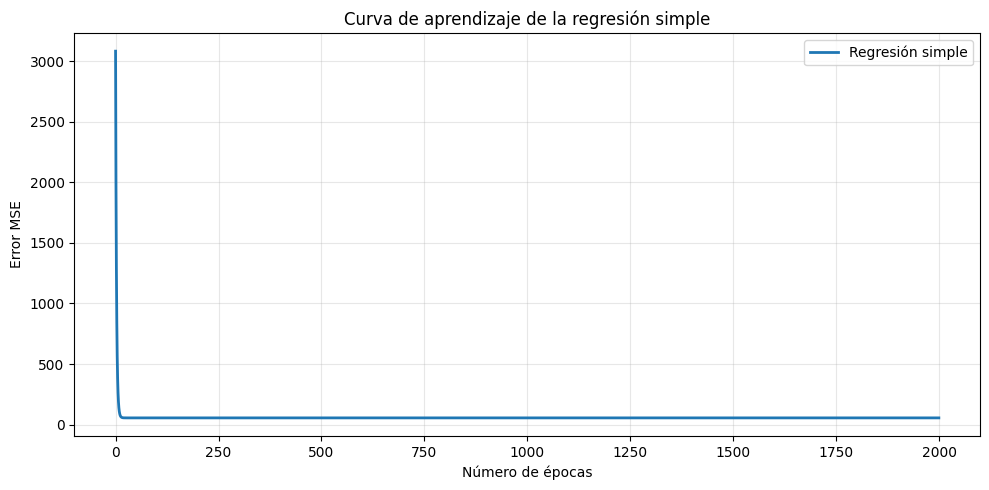

In [6]:
# Curva de aprendizaje de la regresión simple


plt.figure(figsize=(10, 5))


plt.plot(
    historial_simple,
    label="Regresión simple",
    linewidth=2
)


plt.title("Curva de aprendizaje de la regresión simple")
plt.xlabel("Número de épocas")
plt.ylabel("Error MSE")
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

## 4 · Contraste con una librería
Ajusta con `statsmodels` (`smf.ols`) los mismos dos modelos. Guarda `ols_simple` y `ols_control` y crea una tabla
`comparacion` (DataFrame) con tres filas (`pendiente_simple`, `efecto_temp_control`, `efecto_festivo_control`) y dos columnas:
`desde_cero` y `statsmodels`.

In [7]:
# TODO: smf.ols("ocupacion_pct ~ temperatura_c", ...) y "ocupacion_pct ~ temperatura_c + festivo + C(mes)"; params["..."]
ols_simple = smf.ols("ocupacion_pct ~ temperatura_c", data=diaria).fit()
ols_control = smf.ols("ocupacion_pct ~ temperatura_c + festivo + C(mes)", data=diaria).fit()
comparacion = pd.DataFrame({
    "desde_cero": [pendiente_simple, efecto_temp_control, efecto_festivo_control],
    "statsmodels": [ols_simple.params["temperatura_c"], ols_control.params["temperatura_c"], ols_control.params["festivo"]]
}, index=["pendiente_simple", "efecto_temp_control", "efecto_festivo_control"])
assert comparacion.shape == (3, 2), "La tabla debe tener 3 filas y 2 columnas"
assert np.allclose(comparacion["desde_cero"], comparacion["statsmodels"], atol=0.02), f"Tu implementación no coincide con statsmodels:\n{comparacion}"
print("Punto de control 3 superado")
print(comparacion.round(3))
print(ols_control.summary())

Punto de control 3 superado
                        desde_cero  statsmodels
pendiente_simple            -1.860       -1.860
efecto_temp_control         -0.089       -0.089
efecto_festivo_control       9.111        9.111
                            OLS Regression Results                            
Dep. Variable:          ocupacion_pct   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.574
Method:                 Least Squares   F-statistic:                     114.6
Date:                Fri, 06 Nov 2026   Prob (F-statistic):          6.88e-193
Time:                        13:04:47   Log-Likelihood:                -3560.7
No. Observations:                1096   AIC:                             7149.
Df Residuals:                    1082   BIC:                             7219.
Df Model:                          13                                         
Covariance Type:            nonrobust                                

## 5 · Responder con estadística
Con `ols_control` y con un contraste, calcula y guarda:
- `p_temp_control`: p-valor del efecto de la temperatura **con control**.
- `ic_festivo`: intervalo de confianza del 95 % del efecto del festivo (tupla de dos números, con `conf_int`).
- `p_festivo_ttest`: p-valor del t de Welch entre ocupación de festivos y no festivos.
- `r2_control`: R² del modelo con control.

In [8]:
# TODO: ols_control.pvalues[...], ols_control.conf_int().loc["festivo"], stats.ttest_ind(..., equal_var=False).pvalue, ols_control.rsquared
festivos = diaria.loc[diaria["festivo"] == 1, "ocupacion_pct"]
no_festivos = diaria.loc[diaria["festivo"] == 0, "ocupacion_pct"]
p_temp_control = ols_control.pvalues["temperatura_c"]
ic_festivo = tuple(ols_control.conf_int().loc["festivo"])
p_festivo_ttest = stats.ttest_ind(festivos, no_festivos, equal_var=False).pvalue
r2_control = ols_control.rsquared
print(round(p_temp_control, 3), tuple(round(x, 2) for x in ic_festivo), p_festivo_ttest, round(r2_control, 3))
assert p_temp_control > 0.05, f"Con control de mes, la temperatura no es significativa (p ≈ 0.48) y tienes p = {p_temp_control:.3f}"
assert abs(ic_festivo[0] - 7.35) < 0.05 and abs(ic_festivo[1] - 10.87) < 0.05, f"El IC del festivo debería ser ≈ (7.35, 10.87) y tienes {ic_festivo}"
assert p_festivo_ttest < 1e-20, "El t-test de festivos debe dar un p-valor minúsculo"
assert 0.55 < r2_control < 0.62, f"El R² del modelo con control ≈ 0.58 y tienes {r2_control:.3f}"
print("Punto de control 4 superado")

0.481 (7.35, 10.87) 1.1270261040333233e-30 0.579
Punto de control 4 superado


## 6 · Respuesta al cliente (máx. 150 palabras)
Escribe en la celda de abajo, **para una persona no técnica**:
1. **Respuesta directa** a las dos preguntas (¿la temperatura? ¿los festivos?) con las cifras clave y su incertidumbre.
2. **Recomendación accionable** (personal, precios).
3. **Límites:** ¿qué NO puedes afirmar? (correlación frente a causalidad, variable de confusión "mes", datos sintéticos de un solo alojamiento, R²).
4. **IA responsable:** una frase sobre riesgos o cautelas (por ejemplo, usar el modelo para fijar precios sin revisión humana, o presentarlo como causal).

> **Mi respuesta al cliente:**
>
Hemos analizado tres años de datos de ocupación. Al tener en cuenta el mes y los festivos, la temperatura apenas cambia la ocupación: baja 0,09 puntos por grado, pero el resultado no es significativo (p = 0,481). Por tanto, no podemos afirmar que influya.
Los días festivos sí muestran un efecto positivo: la ocupación aumenta unos 9,11 puntos, con un intervalo de confianza del 95 % entre 7,35 y 10,87 puntos.
Recomendamos tener en cuenta los festivos al organizar los turnos del personal y prever una mayor demanda. No recomendamos cambiar los precios basándonos únicamente en este análisis.
Estos datos no demuestran que los festivos sean la causa del aumento. El estudio utiliza datos sintéticos de un solo alojamiento y solo tres años, por lo que sus conclusiones tienen límites.
La IA puede ayudar a analizar datos, pero cualquier decisión sobre precios o personal debe revisarla una persona.


## 7 · Reproducibilidad: antes de entregar
- [ ] *Reiniciar y ejecutar todo* funciona sin errores.
- [ ] Se entrega `turisdata_reto.db` (o el cuaderno lo crea al ejecutarse) y las versiones de las librerías están indicadas en el README de vuestro repositorio (o en una celda `!pip freeze`).
- [ ] Todas las gráficas tienen título y ejes en español.
- [ ] La respuesta al cliente cabe en 150 palabras.



In [9]:
texto = """Hemos analizado tres años de datos de ocupación. Al tener en cuenta el mes y los festivos, la temperatura apenas cambia la ocupación: baja 0,09 puntos por grado, pero el resultado no es significativo (p = 0,481). Por tanto, no podemos afirmar que influya.
Los días festivos sí muestran un efecto positivo: la ocupación aumenta unos 9,11 puntos, con un intervalo de confianza del 95 % entre 7,35 y 10,87 puntos.
Recomendamos tener en cuenta los festivos al organizar los turnos del personal y prever una mayor demanda. No recomendamos cambiar los precios basándonos únicamente en este análisis.
Estos datos no demuestran que los festivos sean la causa del aumento. El estudio utiliza datos sintéticos de un solo alojamiento y solo tres años, por lo que sus conclusiones tienen límites.
La IA puede ayudar a analizar datos, pero cualquier decisión sobre precios o personal debe revisarla una persona."""
print(len(texto.split()), "palabras")

148 palabras


In [10]:
print("Filas de datos:", len(diaria))
print("Variables disponibles:", diaria.columns.tolist())
print("Datos de ocupación:", len(y))

Filas de datos: 1096
Variables disponibles: ['fecha', 'ocupacion_pct', 'temperatura_c', 'festivo', 'precio_medio', 'mes']
Datos de ocupación: 1096


Interpretación de los resultados estadísticos
Temperatura: El coeficiente es -0,089 y el p-valor es 0,481. Como es superior a 0,05 y el intervalo de confianza incluye el cero, no podemos afirmar que la temperatura influya en la ocupación una vez controlados el mes y los festivos.
Festivos: El coeficiente es +9,11. Esto significa que la ocupación aumenta aproximadamente 9,11 puntos porcentuales en los días festivos. Su intervalo de confianza del 95 % está entre 7,35 y 10,87 puntos. Como el intervalo no incluye el cero, el resultado es estadísticamente significativo.
R²: El modelo explica aproximadamente el 57,9 % de las variaciones de ocupación. El porcentaje restante depende de otros factores que no están incluidos en el modelo.

Respuesta al cliente
Hemos analizado tres años de datos de ocupación del alojamiento.
Los resultados indican que la temperatura apenas influye en la ocupación cuando tenemos en cuenta el mes y los días festivos. Por tanto, no podemos afirmar que exista una relación significativa.
En cambio, los días festivos están asociados con un aumento de aproximadamente 9,11 puntos porcentuales de ocupación. El intervalo de confianza del 95 % se encuentra entre 7,35 y 10,87 puntos.
Recomendamos tener en cuenta los festivos para organizar los turnos del personal y prever una mayor demanda.
No recomendamos modificar los precios basándonos únicamente en este análisis.
Hay que tener en cuenta que los datos son sintéticos, corresponden a un solo alojamiento y abarcan tres años. Además, estos resultados muestran asociaciones, pero no demuestran que los festivos sean la causa del aumento de ocupación

In [11]:
# Crear variables para representar los meses
meses = pd.get_dummies(
    diaria["mes"],
    drop_first=True,
    dtype=float
)


# Juntar temperatura, festivos y meses
M = pd.concat([
    diaria[["temperatura_c", "festivo"]].astype(float),
    meses
], axis=1)


# Calcular medias y desviaciones
medias, desv = M.mean(), M.std()


# Preparar la matriz de datos
Xc = np.column_stack([
    np.ones(len(M)),
    ((M - medias) / desv).to_numpy()
])


# Entrenar el modelo
wc, historial_c = entrenar(Xc, y, 0.1, 2000)


# Calcular los efectos
efecto_temp_control = wc[1] / desv["temperatura_c"]
efecto_festivo_control = wc[2] / desv["festivo"]


print("Efecto de la temperatura:", efecto_temp_control)
print("Efecto de los festivos:", efecto_festivo_control)

Efecto de la temperatura: -0.08906123549266555
Efecto de los festivos: 9.110624929160661


In [12]:
print(f"Efecto temperatura: {efecto_temp_control:.4f}")
print(f"Efecto festivos: {efecto_festivo_control:.4f}")

Efecto temperatura: -0.0891
Efecto festivos: 9.1106


In [13]:
# Importar la herramienta estadística
import statsmodels.formula.api as smf


# Crear el modelo con temperatura, festivos y mes
ols_control = smf.ols(
    "ocupacion_pct ~ temperatura_c + festivo + C(mes)",
    data=diaria
).fit()


# Comparar los resultados de ambos métodos
comparacion = pd.DataFrame({
    "Variable": ["Temperatura", "Festivos"],
    "Descenso del gradiente": [
        efecto_temp_control,
        efecto_festivo_control
    ],
    "Statsmodels": [
        ols_control.params["temperatura_c"],
        ols_control.params["festivo"]
    ]
})


print(comparacion)

      Variable  Descenso del gradiente  Statsmodels
0  Temperatura               -0.089061    -0.089061
1     Festivos                9.110625     9.110625


In [14]:
# Obtener los intervalos de confianza
intervalos = ols_control.conf_int()


# Crear una tabla con los resultados
resultados = pd.DataFrame({
    "Coeficiente": ols_control.params[["temperatura_c", "festivo"]],
    "P-valor": ols_control.pvalues[["temperatura_c", "festivo"]],
    "IC inferior": intervalos.loc[["temperatura_c", "festivo"], 0],
    "IC superior": intervalos.loc[["temperatura_c", "festivo"], 1]
})


print(resultados)


# Obtener el porcentaje explicado por el modelo
print("R²:", ols_control.rsquared)

               Coeficiente       P-valor  IC inferior  IC superior
temperatura_c    -0.089061  4.805154e-01    -0.336685     0.158562
festivo           9.110625  2.606277e-23     7.354746    10.866504
R²: 0.5793330599192615


EXTRA 1. Correlación no significa causalidad
En la regresión simple observamos que, cuando aumenta la temperatura, la ocupación disminuye aproximadamente 1,86 puntos por grado.
Sin embargo, al añadir el control por mes y festivos, el efecto de la temperatura pasa a ser de aproximadamente -0,089 puntos.
Esto ocurre porque la época del año influye tanto en la temperatura como en la ocupación. Por ejemplo, los meses de invierno pueden tener temperaturas diferentes y también una ocupación turística distinta.
Por tanto, la relación inicial entre temperatura y ocupación estaba mezclada con el efecto del mes.
Conclusión: que dos variables estén relacionadas no significa que una sea la causa de la otra. Controlar por mes nos permite separar mejor sus efectos, aunque tampoco demuestra por sí solo una relación causal.

In [15]:
# Comparar el efecto de la temperatura
# antes y después de controlar por mes y festivos


comparacion_temperatura = pd.DataFrame({
    "Modelo": [
        "Regresión simple",
        "Modelo con control"
    ],
    "Efecto temperatura": [
        pendiente_simple,
        efecto_temp_control
    ]
})


print(comparacion_temperatura.round(4))

               Modelo  Efecto temperatura
0    Regresión simple             -1.8602
1  Modelo con control             -0.0891


EXTRA 2. Comparación de tasas de aprendizaje
Vamos a entrenar el modelo utilizando diferentes tasas de aprendizaje para comprobar cómo afecta este parámetro a la velocidad de convergencia.
Una tasa demasiado pequeña hace que el aprendizaje sea lento. Una tasa adecuada permite llegar al resultado más rápidamente. Una tasa demasiado grande puede provocar que el modelo no consiga converger.

In [16]:
# Comparar diferentes tasas de aprendizaje


tasas = [0.001, 0.01, 0.1, 0.5]


resultados_tasas = {}


for tasa in tasas:
    pesos, historial_tasa = entrenar(X, y, tasa, 2000)


    resultados_tasas[tasa] = historial_tasa


    print(
        f"Tasa {tasa}: "
        f"Error inicial = {historial_tasa[0]:.4f}, "
        f"Error final = {historial_tasa[-1]:.6f}"
    )

Tasa 0.001: Error inicial = 4764.0976, Error final = 57.523722
Tasa 0.01: Error inicial = 4595.7974, Error final = 55.950542
Tasa 0.1: Error inicial = 3081.2643, Error final = 55.950542
Tasa 0.5: Error inicial = 55.9506, Error final = 55.950542


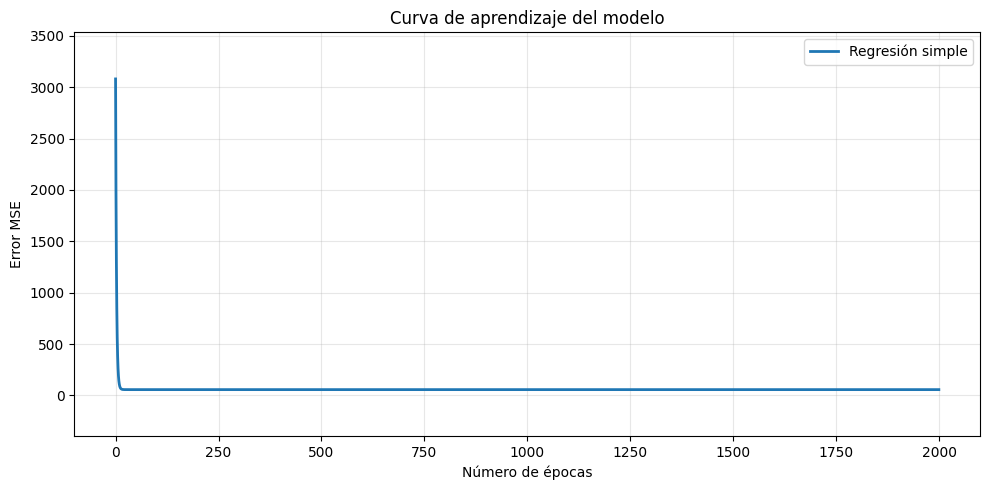

In [17]:
plt.figure(figsize=(10, 5))


plt.plot(
    historial,
    label="Regresión simple",
    linewidth=2
)


# Ajustar el eje vertical para apreciar los cambios
error_min = min(historial)
error_max = max(historial)
margen = max((error_max - error_min) * 0.15, 0.000001)


plt.ylim(error_min - margen, error_max + margen)


plt.title("Curva de aprendizaje del modelo")
plt.xlabel("Número de épocas")
plt.ylabel("Error MSE")
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

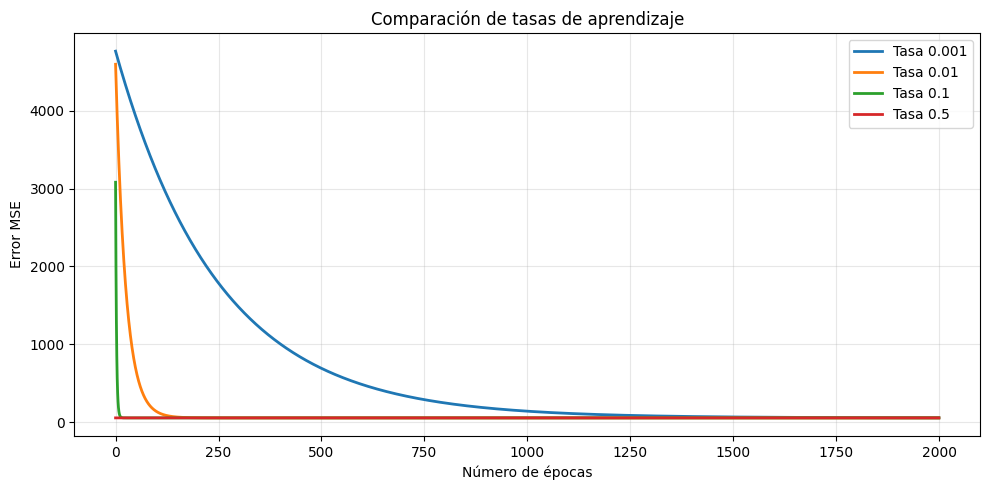

In [18]:
# Gráfico comparativo de las tasas de aprendizaje


plt.figure(figsize=(10, 5))


for tasa, historial_tasa in resultados_tasas.items():
    plt.plot(
        historial_tasa,
        label=f"Tasa {tasa}",
        linewidth=2
    )


plt.title("Comparación de tasas de aprendizaje")
plt.xlabel("Número de épocas")
plt.ylabel("Error MSE")
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

Interpretación del gráfico comparativo
La tasa de aprendizaje influye en la velocidad con la que el modelo reduce el error.
Con una tasa de 0.001 el aprendizaje es lento. Con 0.01 mejora la velocidad y con 0.1 y 0.5 se alcanza rápidamente el mismo error final.
Para este ejercicio elegimos 0.1 porque consigue converger rápidamente sin necesidad de utilizar una tasa tan elevada como 0.5.
Las cuatro tasas llegan a un resultado estable, aunque necesitan diferente número de épocas para conseguirlo.

Conclusión: comparación de tasas de aprendizaje
Hemos probado cuatro tasas de aprendizaje: 0.001, 0.01, 0.1 y 0.5.
La tasa 0.001 aprende demasiado despacio y necesita muchas épocas para reducir el error. Las tasas 0.01, 0.1 y 0.5 consiguen reducirlo mucho más rápidamente.
La comparación demuestra que elegir una tasa de aprendizaje adecuada es importante para conseguir que el algoritmo aprenda de forma eficiente.
No debemos elegir únicamente la tasa más rápida: también debemos comprobar que el error final sea bajo y que el modelo converja correctamente.

### EXTRA 3. Presentación mejorada de los gráficos

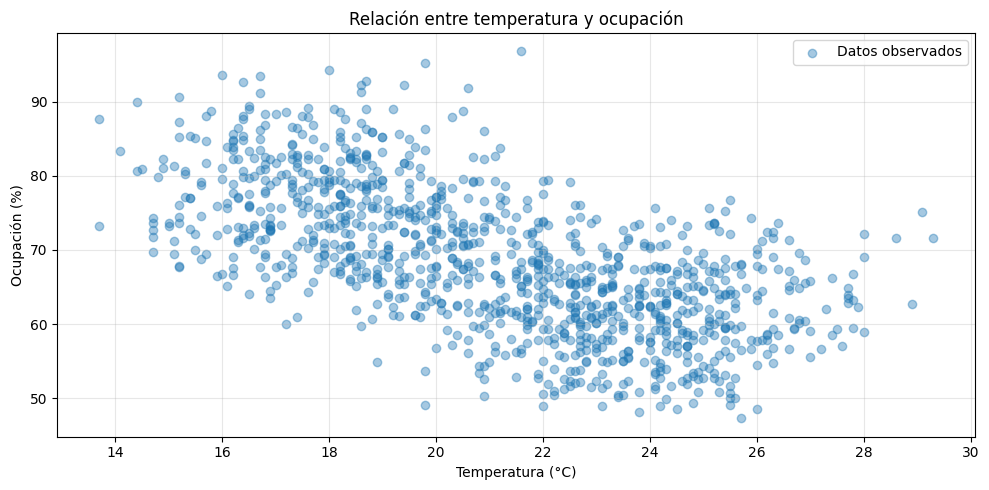

In [19]:
plt.figure(figsize=(10, 5))


plt.scatter(
    diaria["temperatura_c"],
    diaria["ocupacion_pct"],
    alpha=0.4,
    label="Datos observados"
)


plt.xlabel("Temperatura (°C)")
plt.ylabel("Ocupación (%)")
plt.title("Relación entre temperatura y ocupación")
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

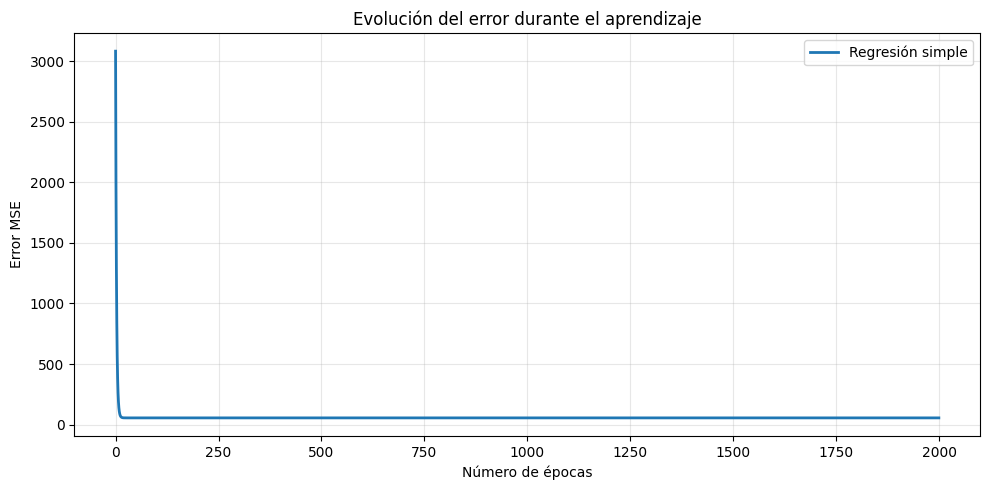

In [20]:
plt.figure(figsize=(10, 5))


plt.plot(
    historial,
    label="Regresión simple",
    linewidth=2
)


plt.title("Evolución del error durante el aprendizaje")
plt.xlabel("Número de épocas")
plt.ylabel("Error MSE")
plt.legend()
plt.grid(True, alpha=0.3)


plt.tight_layout()
plt.show()

In [21]:
con.close()